# 분석 대상 원본 데이터 시각화 (전처리 전)

이 노트북은 전처리가 적용되지 않은 **순수 원본(Raw) 피처 데이터**를 확대해서 보여줍니다. 
데이터의 노이즈, 드리프트(Drift), 이상치 패턴을 눈으로 직접 확인하시고, 어떤 전처리가 추가로 필요할지 판단하는 데 도움을 드리기 위해 작성되었습니다.

In [14]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os
import warnings
warnings.filterwarnings('ignore')

# 한글 폰트 완벽 설정
def setup_korean_font():
    candidates = [
        'Apple SD Gothic Neo', 
        'AppleGothic', 
        'Nanum Gothic', 
        'NanumGothic',
        'Malgun Gothic'
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in candidates:
        if name in available:
            matplotlib.rcParams['font.family'] = name
            matplotlib.rcParams['axes.unicode_minus'] = False
            return name
    
    # 맥 OS 직접 경로 탐색
    direct_paths = [
        '/System/Library/Fonts/Supplemental/AppleGothic.ttf',
        '/System/Library/Fonts/AppleSDGothicNeo.ttc',
    ]
    for path in direct_paths:
        if os.path.exists(path):
            try:
                prop = fm.FontProperties(fname=path)
                matplotlib.rcParams['font.family'] = prop.get_name()
                matplotlib.rcParams['axes.unicode_minus'] = False
                return prop.get_name()
            except Exception:
                pass
    return 'DejaVu Sans'

FONT = setup_korean_font()
print(f'적용된 한글 폰트: {FONT}')

# 그래프 스타일 설정
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = '#F8F9FA'
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['figure.dpi'] = 120

적용된 한글 폰트: Apple SD Gothic Neo


## 1. 샘플 데이터 로드

In [15]:
SAMPLE_FILE = '../data/진현준/진현준_control.csv'
df = pd.read_csv(SAMPLE_FILE)
df['iso_time'] = pd.to_datetime(df['iso_time'])

# 분석에 사용하는 세그먼트별로 분리 및 정렬
foot_df = df[df['source_segment'] == 'foot'].sort_values('iso_time').reset_index(drop=True)
shank_df = df[df['source_segment'] == 'shank'].sort_values('iso_time').reset_index(drop=True)
hip_df = df[df['source_segment'] == 'hip'].sort_values('iso_time').reset_index(drop=True)

FS = 60.0 # 측정 주파수 (Hz)
print(f'데이터 길이: Foot({len(foot_df)}), Shank({len(shank_df)}), Hip({len(hip_df)})')

데이터 길이: Foot(7241), Shank(7243), Hip(7241)


## 2. 가속도 데이터 (착지 충격 및 케이던스 계산용)

착지 피크가 얼마나 깨끗하게 떨어지는지, 노이즈나 베이스라인 시프트가 있는지 확인합니다. 
**확대 구간**: 달리기 시작 후 안정화된 시점 (약 3분 경과 지점, 180초 ~ 185초 구간)

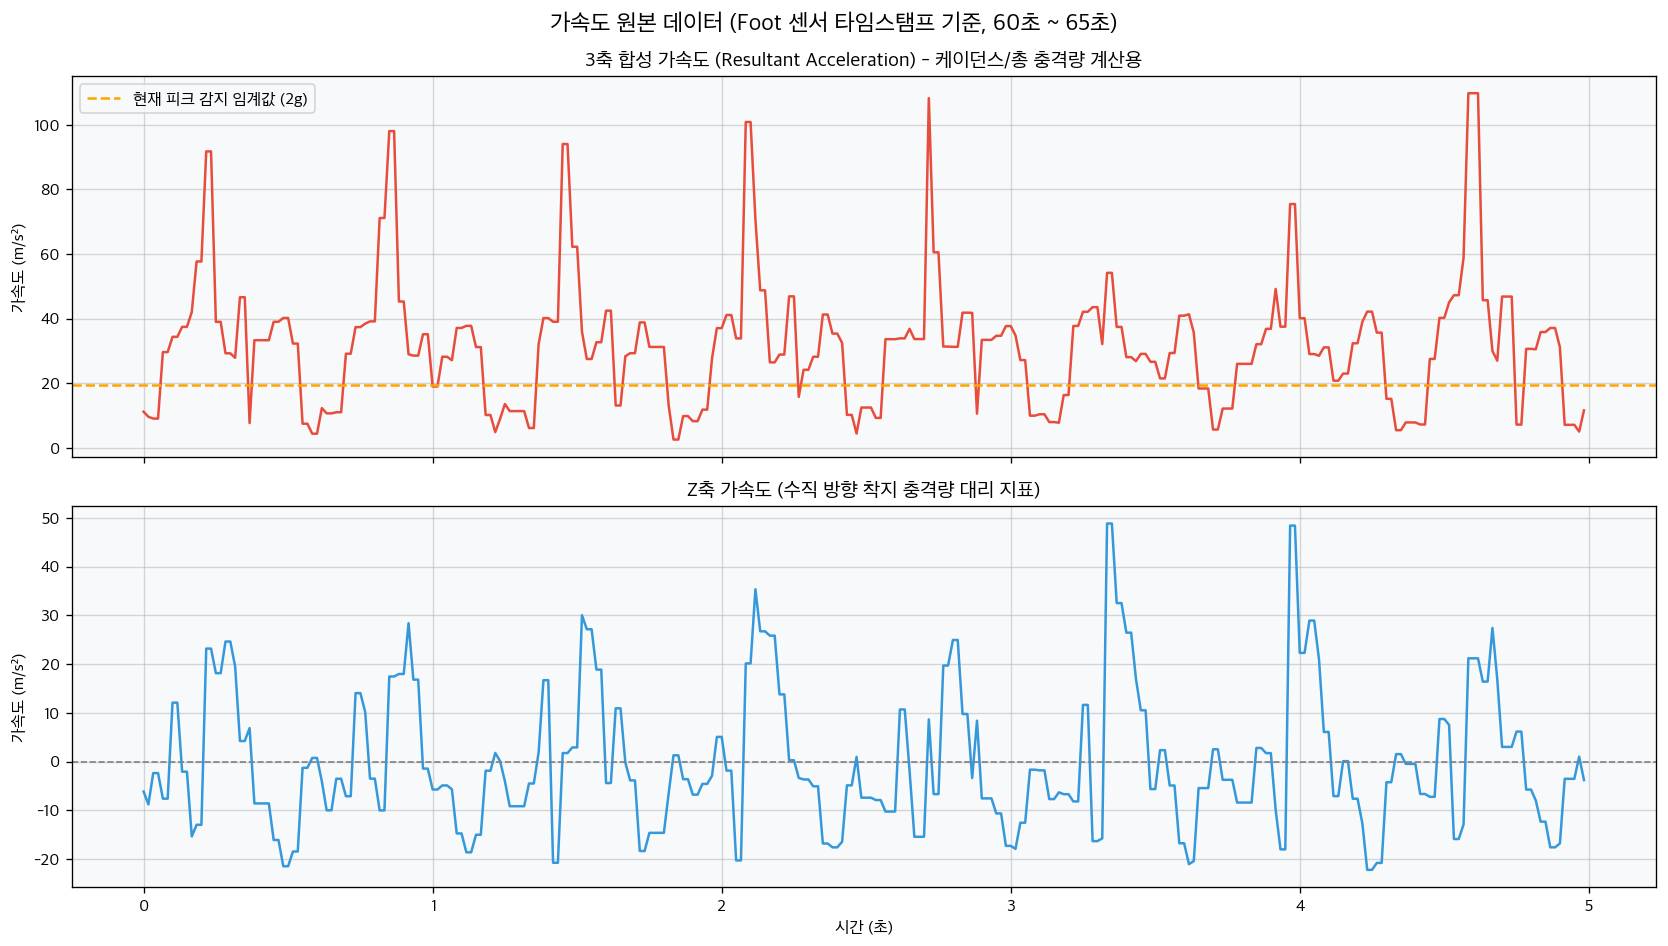

In [16]:
START_SEC = 60  # 3분 경과 지점
WINDOW_SEC = 5   # 5초간 관찰

start_idx = int(START_SEC * FS)
end_idx = int((START_SEC + WINDOW_SEC) * FS)

sub_foot = foot_df.iloc[start_idx:end_idx]
t = np.arange(len(sub_foot)) / FS

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig.suptitle(f'가속도 원본 데이터 (Foot 센서 타임스탬프 기준, {START_SEC}초 ~ {START_SEC+WINDOW_SEC}초)', fontsize=14, fontweight='bold')

# 1. Resultant Acc (케이던스용)
ax1.plot(t, sub_foot['shank_free_acceleration_resultant_m_s2'], color='#E74C3C', linewidth=1.5)
ax1.axhline(2 * 9.81, color='orange', linestyle='--', linewidth=1.5, label='현재 피크 감지 임계값 (2g)')
ax1.set_title('3축 합성 가속도 (Resultant Acceleration) - 케이던스/총 충격량 계산용', fontweight='bold')
ax1.set_ylabel('가속도 (m/s²)')
ax1.legend()
ax1.grid(True)

# 2. Z-axis Acc (충격량 근사용)
ax2.plot(t, sub_foot['shank_free_acceleration_z_m_s2'], color='#3498DB', linewidth=1.5)
ax2.axhline(0, color='gray', linestyle='--', linewidth=1.0)
ax2.set_title('Z축 가속도 (수직 방향 착지 충격량 대리 지표)', fontweight='bold')
ax2.set_ylabel('가속도 (m/s²)')
ax2.set_xlabel('시간 (초)')
ax2.grid(True)

plt.tight_layout()
plt.show()

## 3. 발목 가동 범위 데이터 (Ankle Kinematics)

테이핑 효과를 확인하기 위해 사용하는 발목 각도 원본입니다.

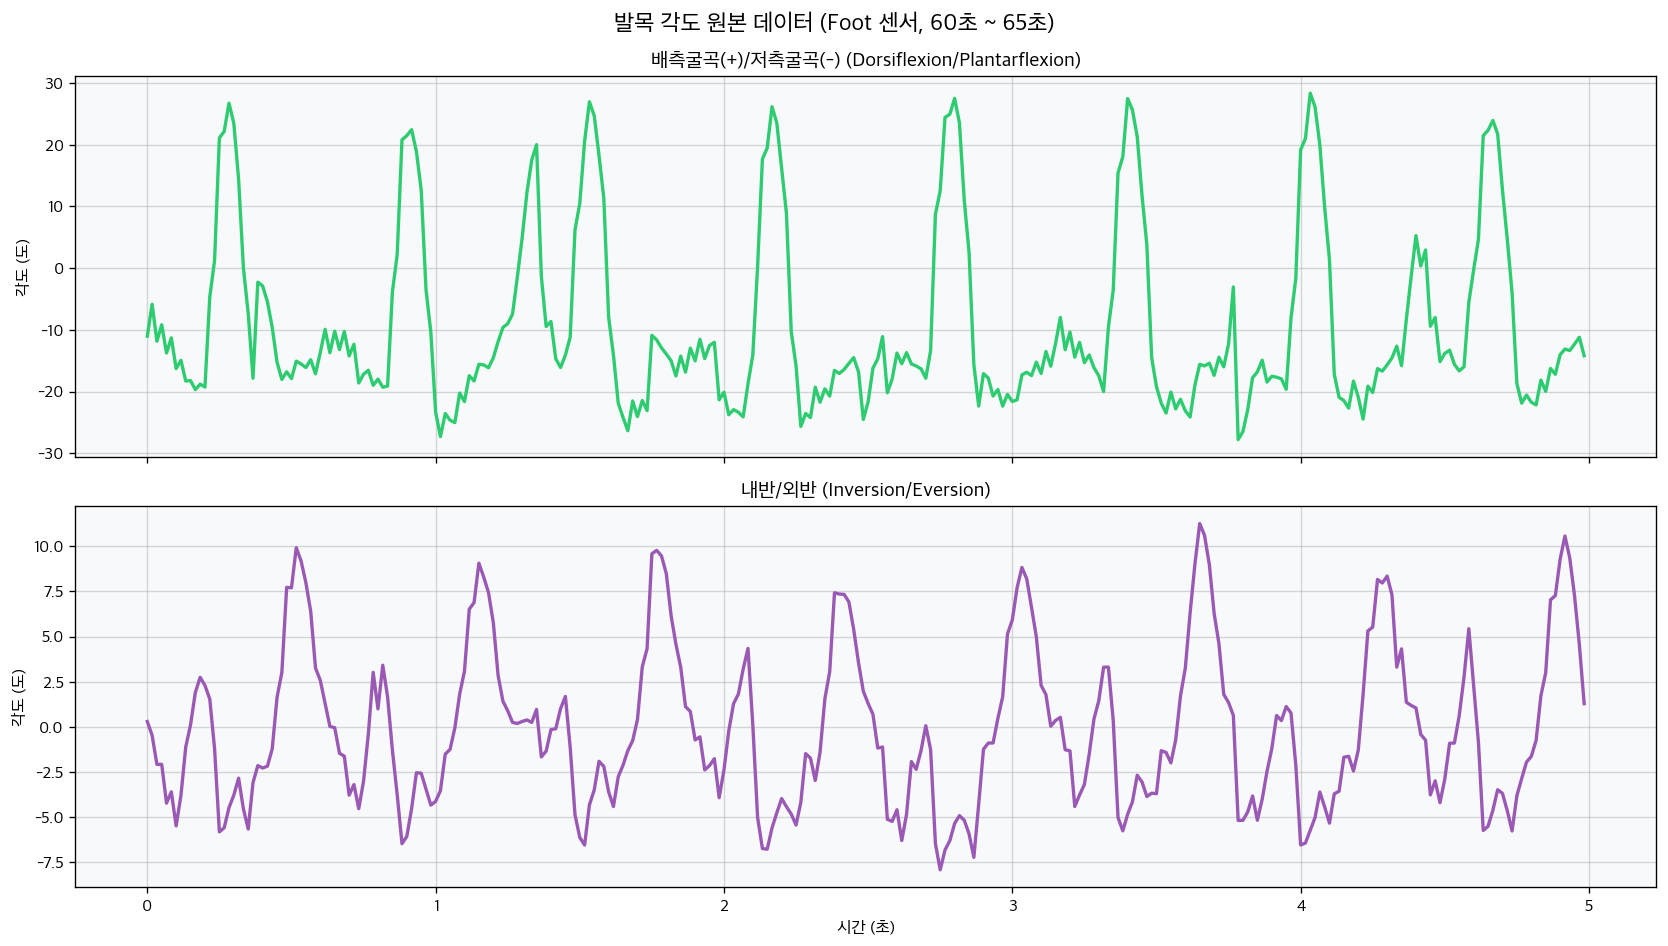

In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig.suptitle(f'발목 각도 원본 데이터 (Foot 센서, {START_SEC}초 ~ {START_SEC+WINDOW_SEC}초)', fontsize=14, fontweight='bold')

# 1. DF/PF
ax1.plot(t, sub_foot['ankle_dorsiflexion_plantarflexion_deg'], color='#2ECC71', linewidth=2)
ax1.set_title('배측굴곡(+)/저측굴곡(-) (Dorsiflexion/Plantarflexion)', fontweight='bold')
ax1.set_ylabel('각도 (도)')
ax1.grid(True)

# 2. Inv/Ev
ax2.plot(t, sub_foot['ankle_inversion_eversion_deg'], color='#9B59B6', linewidth=2)
ax2.set_title('내반/외반 (Inversion/Eversion)', fontweight='bold')
ax2.set_ylabel('각도 (도)')
ax2.set_xlabel('시간 (초)')
ax2.grid(True)

plt.tight_layout()
plt.show()

## 4. 골반 가동 범위 데이터 (Pelvis Kinematics)

메트로놈/테이핑 시 골반의 상하수직진동과 회전을 평가하기 위한 데이터입니다.

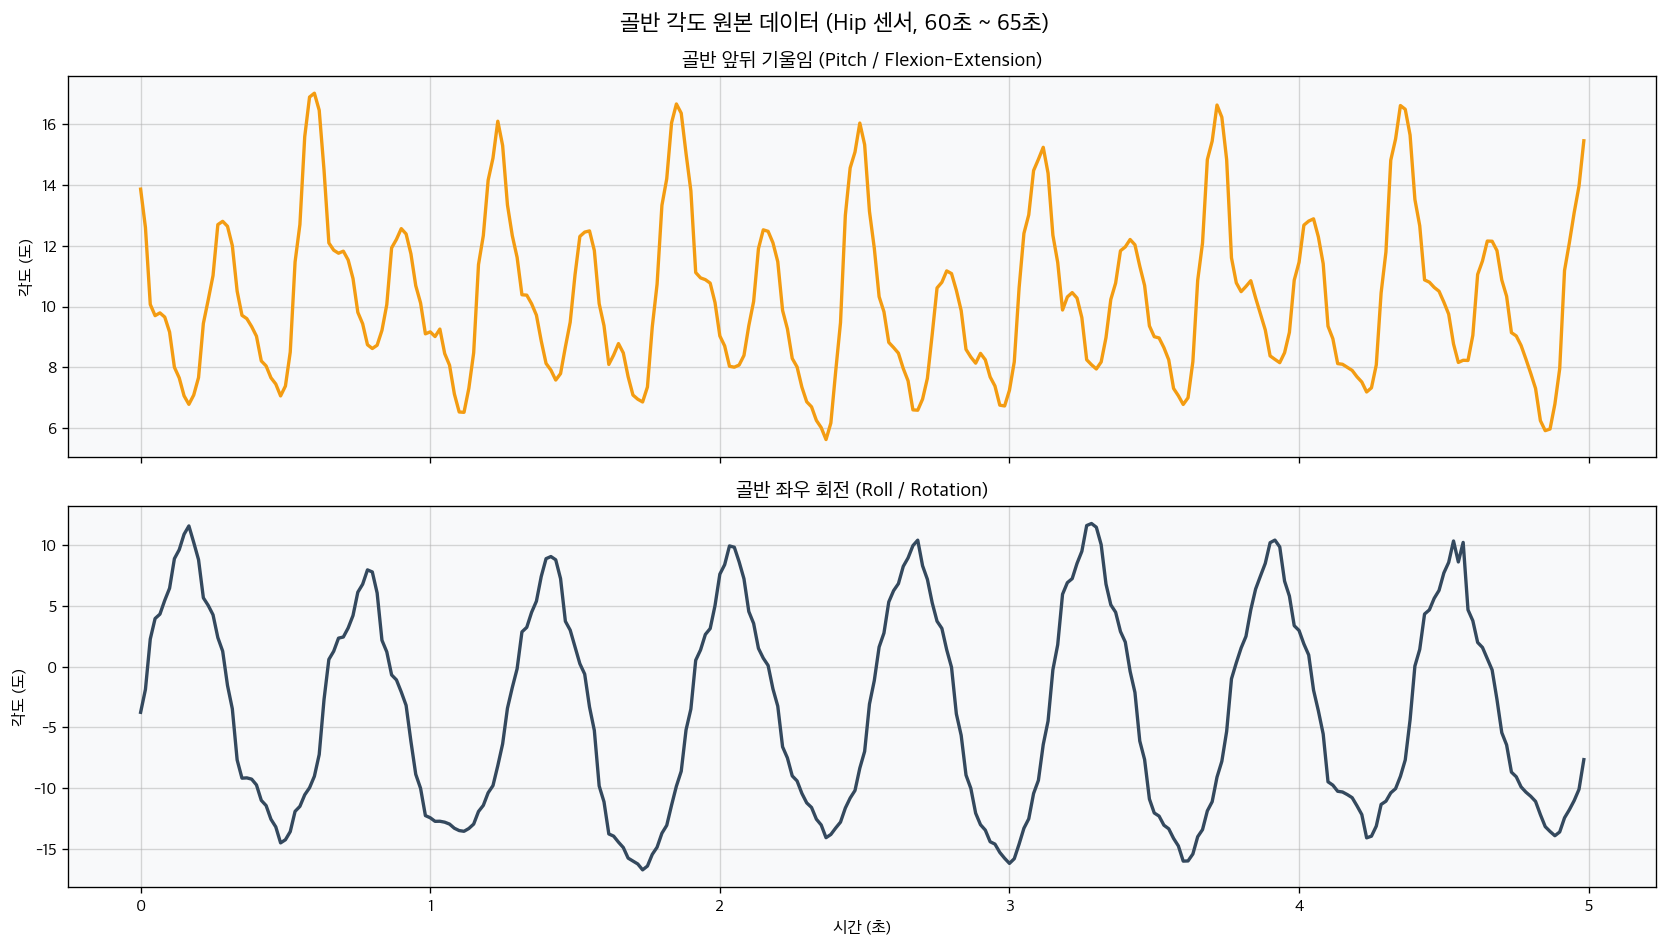

In [18]:
sub_hip = hip_df.iloc[start_idx:end_idx]
t_hip = np.arange(len(sub_hip)) / FS

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig.suptitle(f'골반 각도 원본 데이터 (Hip 센서, {START_SEC}초 ~ {START_SEC+WINDOW_SEC}초)', fontsize=14, fontweight='bold')

# 1. Pitch (Flex/Ext)
ax1.plot(t_hip, sub_hip['hip_quaternion_pitch_deg'], color='#F39C12', linewidth=2)
ax1.set_title('골반 앞뒤 기울임 (Pitch / Flexion-Extension)', fontweight='bold')
ax1.set_ylabel('각도 (도)')
ax1.grid(True)

# 2. Roll (Rotation)
ax2.plot(t_hip, sub_hip['hip_quaternion_roll_deg'], color='#34495E', linewidth=2)
ax2.set_title('골반 좌우 회전 (Roll / Rotation)', fontweight='bold')
ax2.set_ylabel('각도 (도)')
ax2.set_xlabel('시간 (초)')
ax2.grid(True)

plt.tight_layout()
plt.show()

## 5. 센서 장기 드리프트(Drift) 확인

단기(5초) 윈도우가 아닌, 전체 달리기 세션(10분) 동안 베이스라인이 천천히 위/아래로 이동하는 '드리프트 현상'이 있는지 확인합니다.
이 현상이 있다면 단순 Max-Min을 이용한 가동범위 계산은 틀리게 되며, 필터(Low-pass, High-pass)나 이동평균(Moving average) 보정이 필요할 수 있습니다.

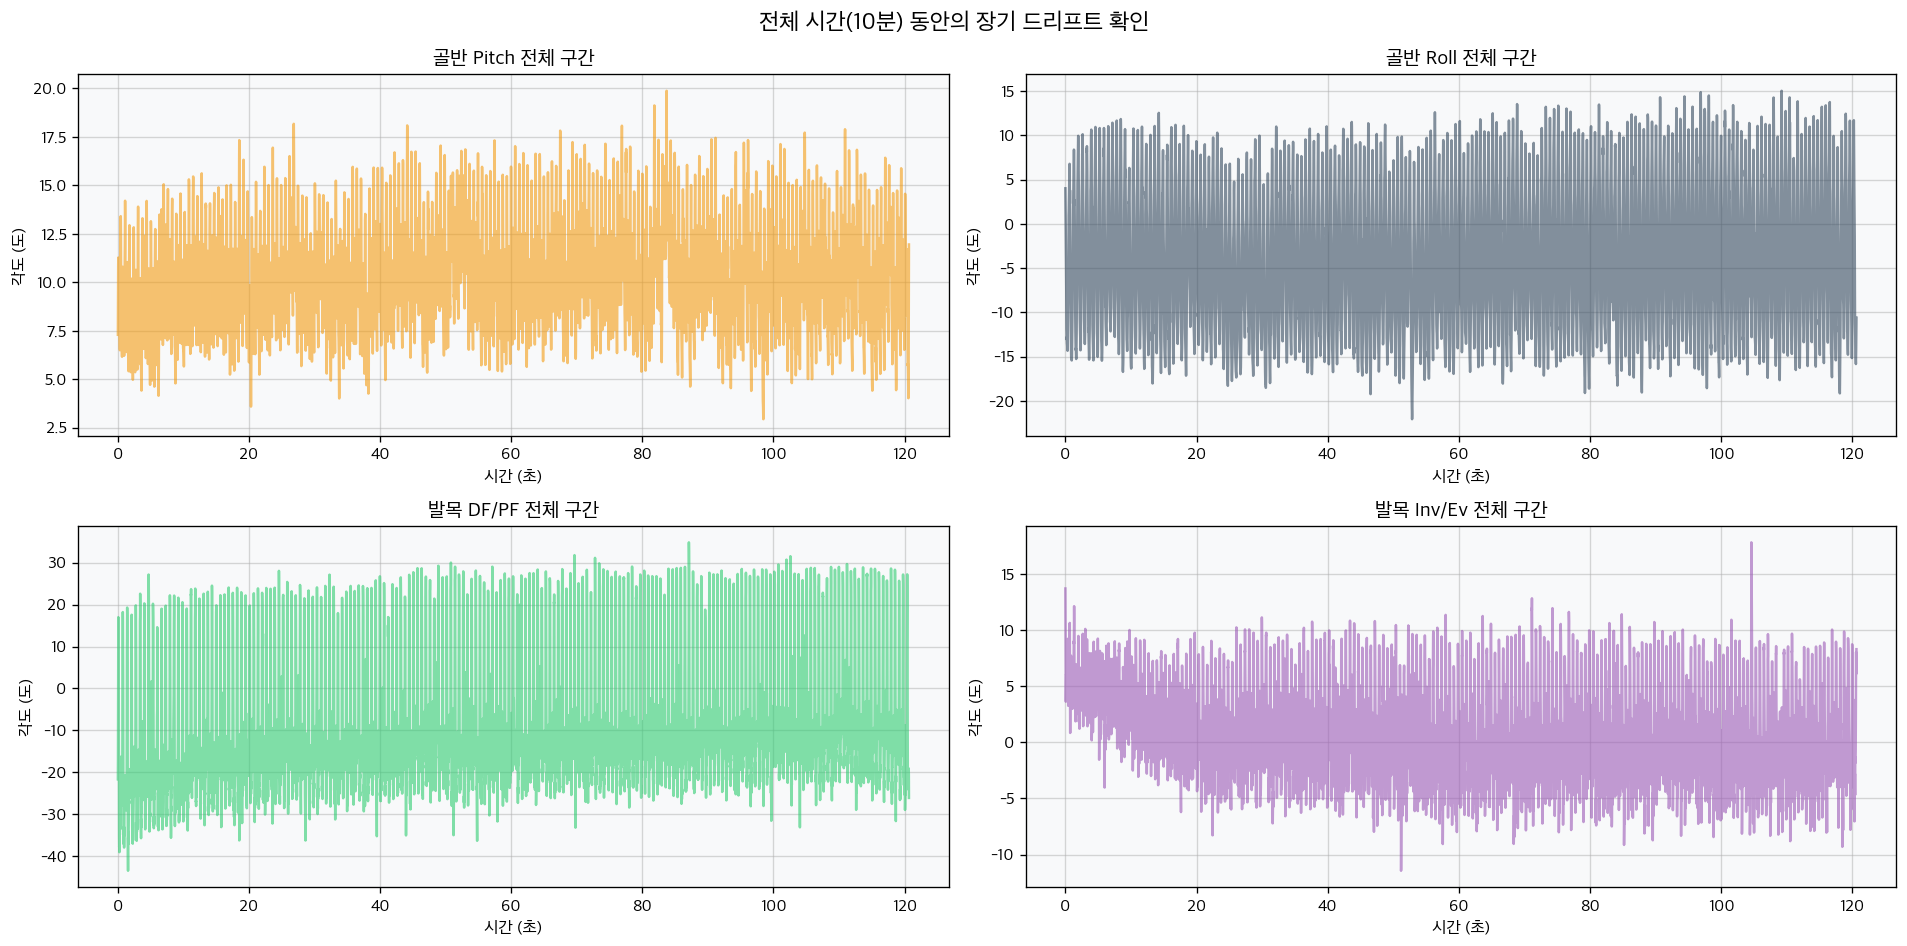

In [19]:
t_full_hip = np.arange(len(hip_df)) / FS
t_full_foot = np.arange(len(foot_df)) / FS

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
fig.suptitle('전체 시간(10분) 동안의 장기 드리프트 확인', fontsize=14, fontweight='bold')

axes[0, 0].plot(t_full_hip, hip_df['hip_quaternion_pitch_deg'], color='#F39C12', alpha=0.6)
axes[0, 0].set_title('골반 Pitch 전체 구간')
axes[0, 0].grid(True)

axes[0, 1].plot(t_full_hip, hip_df['hip_quaternion_roll_deg'], color='#34495E', alpha=0.6)
axes[0, 1].set_title('골반 Roll 전체 구간')
axes[0, 1].grid(True)

axes[1, 0].plot(t_full_foot, foot_df['ankle_dorsiflexion_plantarflexion_deg'], color='#2ECC71', alpha=0.6)
axes[1, 0].set_title('발목 DF/PF 전체 구간')
axes[1, 0].grid(True)

axes[1, 1].plot(t_full_foot, foot_df['ankle_inversion_eversion_deg'], color='#9B59B6', alpha=0.6)
axes[1, 1].set_title('발목 Inv/Ev 전체 구간')
axes[1, 1].grid(True)

for ax in axes.flat:
    ax.set_xlabel('시간 (초)')
    ax.set_ylabel('각도 (도)')

plt.tight_layout()
plt.show()

## 🛑 추가 전처리 고려사항 가이드
위 그래프를 보시고 결과값이 튀는 원인으로 의심되는 부분을 찾아보세요.

1. **베이스라인 시프트 (Drift)**:
   - 맨 마지막 '전체 구간' 그래프에서 각도 중심축이 시간이 지남에 따라 서서히 위나 아래로 쏠리는 현상이 보이나요?
   - **조치법**: Butterworth High-pass 필터 적용 (0.1Hz ~ 0.5Hz)

2. **가속도 노이즈 (High-frequency noise)**:
   - 가속도 5초 구간 그래프에 착지(Peak) 순간 외에 자잘하게 위아래로 매우 심하게 떨리는 잔진동이 큰가요?
   - **조치법**: Butterworth Low-pass 필터 적용 (10Hz ~ 20Hz)

3. **피크(Peak) 감지 오류**:
   - 가속도 주황색 점선(2g 임계값)을 착지 피크가 제대로 뚫지 못하거나, 한 번 착지하는데 선을 두세 번 넘어가나요?
   - **조치법**: `height`, `prominence`, `distance` 파라미터 미세 조정 (예: `height=2g` -> `3g`로 상향, 혹은 반대)


## 6. 동적 임계값 및 필터링(Robust Peak Detection) 검증
새롭게 도입한 Low-pass Filter(15Hz)와 동적 임계값(Dynamic threshold)이 이중 피크(Double-counting) 문제를 어떻게 해결했는지 시각적으로 확인합니다.


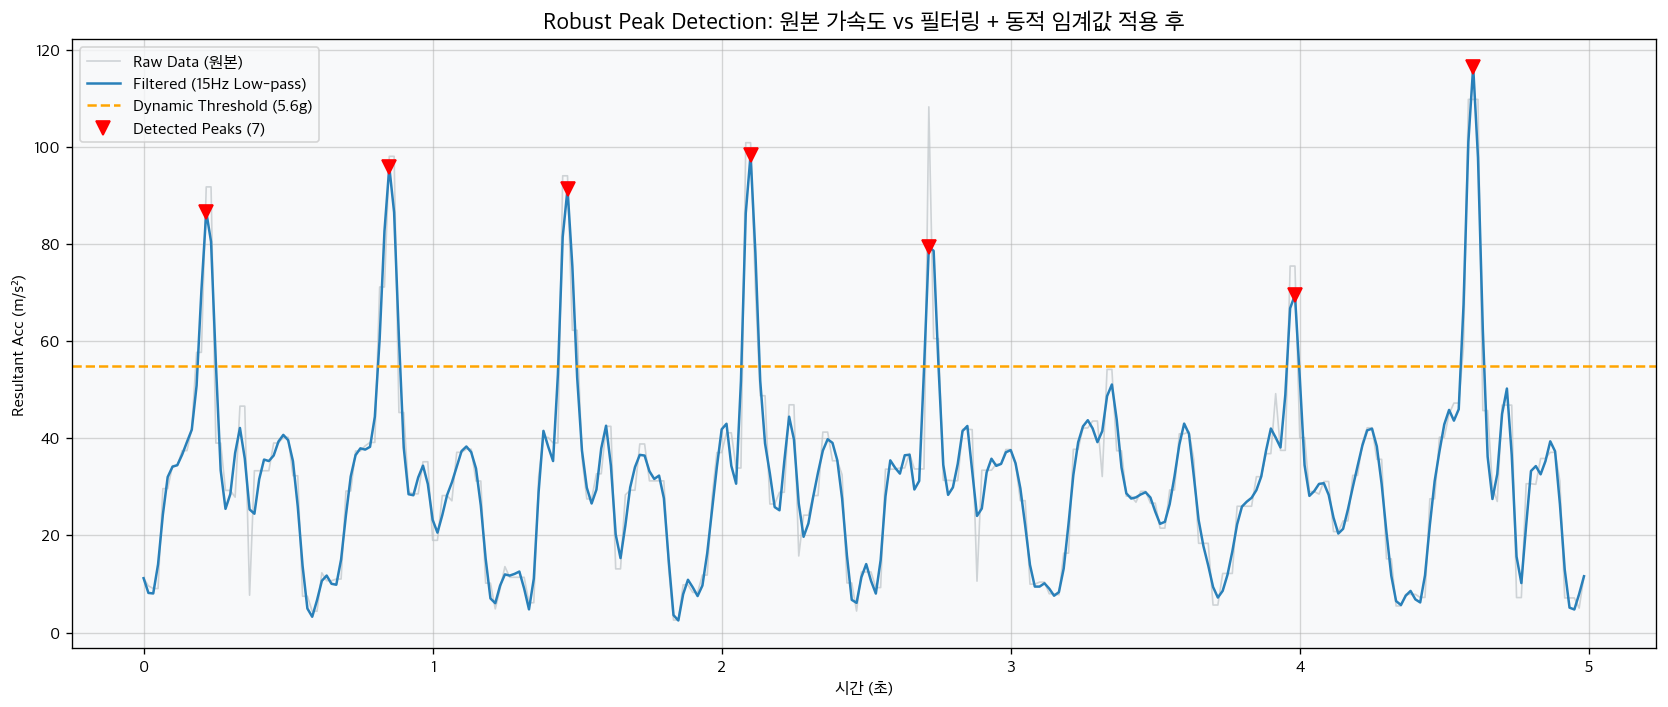

Bad pipe message: %s [b'\x84D\xcc\x90\xc0u\x8e\xe1\x1a,\xa1=\x9d\xa3~IR( \xfc\x08\xbe\xac\xbf\xef\x14k7"\xc0,Y\xe0F\x1a\x99\x04pKbV\x7f\x0f\x16\xcf\x8d\xe6|.\xd1\x8f\x00$\x13\x01\x13\x02\x13\x03\xc0/\xc0+\xc00\xc0,\xc0\'\xcc\xa9\xcc\xa8\xc0\t\xc0\x13\xc0\n\xc0\x14\x00\x9c\x00\x9d\x00/\x005\x01\x00\x00p\x00\x17\x00\x00\xff']
Bad pipe message: %s [b'']
Bad pipe message: %s [b'']
ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/Users/ryutt/Desktop/mini_ryutt/tetoronom/.venv/lib/python3.14/site-packages/zmq/eventloop/zmqstream.py", line 565, in _log_error
    f.result()
    ~~~~~~~~^^
  File "/Users/ryutt/Desktop/mini_ryutt/tetoronom/.venv/lib/python3.14/site-packages/ipykernel/kernelbase.py", line 348, in dispatch_control
    await self.process_control(msg)
  File "/Users/ryutt/Desktop/mini_ryutt/tetoronom/.venv/lib/python3.14/site-packages/ipykernel/kernelbase.py", line 354, in process_control
    idents, msg = self.session.feed_i

In [20]:

from scipy import signal
GRAVITY = 9.81
FS = 60.0

# 1. 필터링 및 동적 임계값 적용
nyq = 0.5 * FS
normal_cutoff = 15.0 / nyq
b, a = signal.butter(4, normal_cutoff, btype='low', analog=False)

raw_acc = sub_foot['shank_free_acceleration_resultant_m_s2'].values
smoothed = signal.filtfilt(b, a, raw_acc)

mean_val = np.mean(smoothed)
std_val = np.std(smoothed)
dynamic_height = max(1.5 * GRAVITY, mean_val + 1.2 * std_val)
dynamic_prominence = max(0.5 * GRAVITY, std_val * 0.5)
min_dist_ms = 280.0

peaks, _ = signal.find_peaks(
    smoothed,
    height=dynamic_height,
    distance=int(FS * min_dist_ms / 1000.0),
    prominence=dynamic_prominence,
)

# 2. 시각화 비교
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(t, raw_acc, color='#BDC3C7', linewidth=1, alpha=0.7, label='Raw Data (원본)')
ax.plot(t, smoothed, color='#2980B9', linewidth=1.5, label='Filtered (15Hz Low-pass)')

ax.axhline(dynamic_height, color='orange', linestyle='--', linewidth=1.5, label=f'Dynamic Threshold ({dynamic_height/9.81:.1f}g)')
ax.plot(t[peaks], smoothed[peaks], 'rv', markersize=8, label=f'Detected Peaks ({len(peaks)})')

ax.set_title('Robust Peak Detection: 원본 가속도 vs 필터링 + 동적 임계값 적용 후', fontproperties=fm.FontProperties(family=FONT, size=14, weight='bold'))
ax.set_ylabel('Resultant Acc (m/s²)', fontproperties=fm.FontProperties(family=FONT))
ax.set_xlabel('시간 (초)', fontproperties=fm.FontProperties(family=FONT))
ax.legend(prop=fm.FontProperties(family=FONT))
ax.grid(alpha=0.5)

plt.tight_layout()
plt.show()
